# Laboratorio de Recomendación — del carrusel "Para ti" a la decisión

Cierra el bloque de Venta Cruzada y Recomendación (la palanca del ARPU). Van a trabajar con una
base **completa**: 8,000 clientes de una cadena de cafeterías, ~10 meses de historial de compras y
un **experimento de 90 días**: a la mitad de los clientes, elegida al azar, la app les mostró un
carrusel **"Para ti"** con los 3 productos más populares que aún no habían comprado. La otra mitad
(control) no vio ningún carrusel.

Este laboratorio repite, sobre la base completa, lo que practicaron en los Breakout Rooms:

| Dónde lo vieron | Qué van a repetir aquí |
|---|---|
| Breakout 2 — La matriz y el coseno | La matriz cliente × producto y la similitud de coseno |
| Breakout 3 — Filtrado por ítem y por cliente | Los dos recomendadores colaborativos (el puntaje es una suma de similitudes) |
| Breakout 4 — Comparar y medir | Hit rate@3, precisión@3 y cobertura con un holdout |

**Los 5 pasos del laboratorio:**
1. Construyen los recomendadores (popularidad, por ítem, por cliente y **uno propio**).
2. Los evalúan con el holdout, **solo en el grupo control** (sin contaminación del carrusel).
3. Miden el **efecto real** del carrusel con el experimento: ΔARPU, margen neto y ΔCLV.
4. Deciden qué recomendador llevarían al siguiente experimento, cuidando a los clientes sin historial.
5. **La revelación**: el dataset trae información oculta (qué compras *ya iban a ocurrir* y cuáles las *causó* el carrusel) que en la vida real nunca existe. La destapan al final y comparan.

Donde dice **`# TODO`** hay algo para que ustedes completen.

> Los efectos de este conjunto de datos están **plantados** por el generador. Sirven para practicar el método;
> no prueban que ninguna cadena real obtenga estos resultados.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD

warnings.filterwarnings("ignore")
VERDE, OSCURO, NARANJA, GRIS = "#00704A", "#11241C", "#C4512F", "#9A988E"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

catalogo = pd.read_csv("data/catalogo.csv")
hist = pd.read_csv("data/ordenes_historial.csv", parse_dates=["order_date"])
hold = pd.read_csv("data/ordenes_holdout.csv", parse_dates=["order_date"])
exp = pd.read_csv("data/experimento.csv")
clientes = pd.read_csv("data/clientes.csv")

print(f"{len(clientes):,} clientes · {len(hist):,} líneas de historial ({hist['order_date'].min().date()} a {hist['order_date'].max().date()})")
print(f"Experimento: {hold['order_date'].min().date()} a {hold['order_date'].max().date()} · "
      f"{(exp['grupo'] == 'tratamiento').sum():,} tratamiento · {(exp['grupo'] == 'control').sum():,} control")
exp.head()

8,000 clientes · 71,523 líneas de historial (2025-09-01 a 2026-06-30)
Experimento: 2026-07-01 a 2026-09-28 · 4,000 tratamiento · 4,000 control


,customer_id,grupo,mostrados
0,1,control,NaN
1,2,tratamiento,Chocolate Caliente|Té Chai|Galleta
2,3,tratamiento,Chocolate Caliente|Té Chai|Galleta
3,4,tratamiento,Chocolate Caliente|Té Chai|Té Verde
4,5,tratamiento,Chocolate Caliente|Té Chai|Galleta


## Paso 1 — construyan los recomendadores

Todos producen una matriz de **puntajes**: una fila por cliente, una columna por producto.
Nada de lo que pasó en el experimento se puede usar para construirlos: **solo el historial**.

Primero la matriz cliente × producto (la misma del Breakout 2).

In [2]:
productos = list(catalogo["item"])
col_agua = productos.index("Agua")

# TODO 1 resuelto: matriz cliente x producto (1 si compro al menos una vez en el historial, 0 si no)
M = (pd.crosstab(hist["customer_id"], hist["item"]) > 0).astype(int).reindex(
    index=clientes["customer_id"], columns=productos, fill_value=0)

X = M.values.astype(np.float32)
print(f"Matriz {X.shape[0]:,} x {X.shape[1]} - densidad {X.mean():.1%} - clientes sin historial: {(X.sum(axis=1) == 0).sum()}")

Matriz 8,000 x 29 - densidad 14.6% - clientes sin historial: 334


Dos piezas que ya vienen armadas: la **popularidad** (a todos lo mismo, lo más comprado) y la función `top_k`,
que se queda con los K productos de mayor puntaje **que el cliente aún no compró** (y sin Agua).

In [3]:
# Respaldo: popularidad (a todos lo mismo, lo más comprado)
S_pop = np.tile(X.sum(axis=0), (len(X), 1))

def top_k(scores, K=3):
    s = np.where(X > 0, -np.inf, scores).astype(np.float64)   # no recomendar lo ya comprado
    s[:, col_agua] = -np.inf                                   # ni el Agua
    return np.argsort(-s, axis=1)[:, :K]

**Filtrado por ítem** (Breakout 3): se compara **producto con producto** (las columnas de `X`), se calcula la
tabla de similitudes **una sola vez**, y el puntaje de cada cliente es la **suma de las similitudes** de cada
candidato con lo que el cliente ya compró.

In [4]:
# TODO 2 resuelto: filtrado por item
S_it = cosine_similarity(X.T)          # similitud de coseno entre las COLUMNAS de X (productos x productos)
np.fill_diagonal(S_it, 0)
S_item = X @ S_it                      # suma de las similitudes con lo que el cliente ya compro
print(S_it.shape, S_item.shape)

(29, 29) (8000, 29)


**Filtrado por cliente** (Breakout 3): se compara **cliente con cliente** (las filas de `X`). Para cada cliente se
buscan sus **K vecinos más parecidos** y el puntaje de cada producto es la suma de las similitudes de los vecinos
que **sí lo compraron** (cada vecino vota con su similitud).

In [5]:
K_VECINOS = 30
S_us = cosine_similarity(X)                   # (clientes x clientes)
np.fill_diagonal(S_us, 0)

S_user = np.zeros_like(X)
for i in range(len(X)):
    # TODO 3 resuelto: K vecinos mas parecidos y sus compras ponderadas por la similitud
    vec = np.argsort(-S_us[i])[:K_VECINOS]    # posiciones de los K mas parecidos
    S_user[i] = S_us[i, vec] @ X[vec]         # similitudes de esos vecinos por sus compras
print(S_us.shape, S_user.shape)

(8000, 8000) (8000, 29)


**Su propio recomendador.** El cuarto método lo eligen ustedes. Algunas ideas:
- **(a)** factorización con `TruncatedSVD(n_components=k)`: `Z = svd.fit_transform(X)` y `S_libre = Z @ svd.components_`
  (cada cliente y cada producto se resumen en unos pocos números "escondidos" de gusto);
- **(b)** el filtrado por cliente con otro K (10, 100, 300…);
- **(c)** un híbrido: mezcla de popularidad normalizada y filtrado por ítem;
- **(d)** cualquier otra idea suya (justifíquenla).

In [6]:
# TODO 4 resuelto: modelo libre = factorizacion de matriz con TruncatedSVD (8 factores latentes de gusto)
nombre_libre = "SVD (8 factores)"
svd = TruncatedSVD(n_components=8, random_state=42)
Z = svd.fit_transform(X)                 # cada cliente resumido en 8 factores
S_libre = Z @ svd.components_            # reconstruccion: puntaje de cada producto para cada cliente

assert isinstance(S_libre, np.ndarray) and S_libre.shape == X.shape, "Completen el TODO 4: S_libre debe tener la misma forma que X"
metodos = {"Popularidad": S_pop, "Filtrado por ítem": S_item, "Filtrado por cliente": S_user, nombre_libre: S_libre}
print("Métodos listos:", list(metodos))

Métodos listos: ['Popularidad', 'Filtrado por ítem', 'Filtrado por cliente', 'SVD (8 factores)']


## Paso 2 — evalúen con el holdout, pero SOLO en el grupo control

- **Entrenamiento** = el historial (de ahí salieron las matrices).
- **Holdout** = los 90 días del experimento. De ahí sale la respuesta: qué productos **nuevos** (que el cliente nunca
  había comprado) probó cada cliente.

**Regla del laboratorio:** el hit rate se mide **solo en el grupo control**. En los tratados, el carrusel influyó en lo
que compraron y ya no es una compra "limpia". En el control, un acierto es una compra que **ocurrió sin ninguna recomendación**.

In [7]:
H = (pd.crosstab(hold["customer_id"], hold["item"]) > 0).astype(int).reindex(index=M.index, columns=productos, fill_value=0).values
NUEVO = H * (1 - X); NUEVO[:, col_agua] = 0              # lo que probó en el holdout y NO había comprado antes (sin Agua)
elegibles = NUEVO.sum(axis=1) > 0
es_control = (exp.set_index("customer_id").loc[M.index, "grupo"] == "control").values

print(f"Clientes que probaron algo NUEVO en los 90 días:")
print(f"  control      : {(elegibles & es_control).sum():,} de {es_control.sum():,} ({elegibles[es_control].mean():.0%})")
print(f"  tratamiento  : {(elegibles & ~es_control).sum():,} de {(~es_control).sum():,} ({elegibles[~es_control].mean():.0%})")

Clientes que probaron algo NUEVO en los 90 días:
  control      : 1,797 de 4,000 (45%)
  tratamiento  : 2,297 de 4,000 (57%)


In [8]:
def hit_rate_at_k(scores, K=3, mask=None):
    top = top_k(scores, K)
    # TODO 5 resuelto: al menos una de las K recomendaciones fue un producto NUEVO que el cliente compro
    filas = np.arange(len(scores))[:, None]
    aciertos = NUEVO[filas, top].sum(axis=1) > 0     # True/False por cliente
    return aciertos[mask].mean()

def precision_at_k(scores, K=3, mask=None):
    top = top_k(scores, K)
    return np.mean([NUEVO[u, top[u]].sum() / K for u in np.where(mask)[0]])

def cobertura(scores, K=3):
    return len(np.unique(top_k(scores, K)))

mask_eval = es_control & elegibles
res = pd.DataFrame({n: {"hit rate@3": hit_rate_at_k(s, mask=mask_eval),
                        "precisión@3": precision_at_k(s, mask=mask_eval),
                        "cobertura (de 28)": cobertura(s)} for n, s in metodos.items()}).T
res.round(3)

,hit rate@3,precisión@3,cobertura (de 28)
Popularidad,0.221,0.078,12.0
Filtrado por ítem,0.401,0.144,28.0
Filtrado por cliente,0.301,0.109,28.0
SVD (8 factores),0.369,0.132,28.0


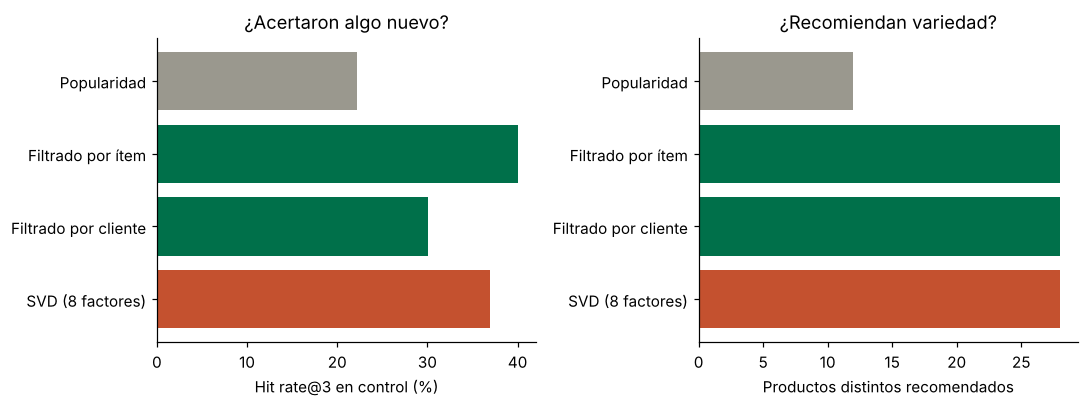

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
colores = [GRIS, VERDE, VERDE, NARANJA]
ax[0].barh(res.index[::-1], res["hit rate@3"][::-1] * 100, color=colores[::-1]); ax[0].set_xlabel("Hit rate@3 en control (%)"); ax[0].set_title("¿Acertaron algo nuevo?")
ax[1].barh(res.index[::-1], res["cobertura (de 28)"][::-1], color=colores[::-1]); ax[1].set_xlabel("Productos distintos recomendados"); ax[1].set_title("¿Recomiendan variedad?")
plt.tight_layout(); plt.show()

**Respuestas Paso 2**

1. Evaluamos solo en el grupo control porque a los tratados el carrusel ya influyo en lo que compraron, asi que una compra suya no es limpia. Si incluyeramos a los tratados el hit rate subiria de forma artificial, porque estariamos premiando compras que el propio carrusel ayudo a provocar, no la capacidad del recomendador de adivinar el gusto.

2. Un acierto en control es una compra que ocurrio sin ninguna recomendacion, es decir, el cliente probo por su cuenta un producto que el metodo tambien le habria sugerido. Mide coincidencia con el gusto real, no causa; el recomendador acerto, pero no causo la compra.

3. Gano el filtrado por item con hit rate 0.401, contra 0.221 de popularidad, una mejora cercana al 80 por ciento. En cobertura el filtrado por item, por cliente y el SVD llegan a 28 productos distintos, mientras que popularidad solo recomienda 12.

## Paso 3 — midan el efecto REAL del carrusel con el experimento

Aquí **sí** usan a los dos grupos. Como la asignación fue al azar, la diferencia entre tratamiento y control es el
efecto causal del carrusel (el que mostró los 3 productos más populares).

Primero el ingreso y el margen de cada cliente en los 90 días (con los precios y márgenes del catálogo).

In [10]:
precio = catalogo.set_index("item")["precio"]
margen = catalogo.set_index("item")["margen"]
hold["ingreso"] = hold["item"].map(precio)
hold["margen_usd"] = hold["ingreso"] * hold["item"].map(margen)
por_cliente = hold.groupby("customer_id")[["ingreso", "margen_usd"]].sum().reindex(clientes["customer_id"]).fillna(0)
ab = exp.set_index("customer_id").join(por_cliente)

trat = ab[ab["grupo"] == "tratamiento"]
ctrl = ab[ab["grupo"] == "control"]
print(f"ARPU de 90 días · control ${ctrl['ingreso'].mean():.2f} · tratamiento ${trat['ingreso'].mean():.2f}")
print(f"Un cliente de control gasta ${ctrl['ingreso'].mean():.2f} en promedio, con desviación estándar ${ctrl['ingreso'].std():.2f}")

ARPU de 90 días · control $15.74 · tratamiento $16.85
Un cliente de control gasta $15.74 en promedio, con desviación estándar $16.71


In [11]:
COSTO_CARRUSEL = 0.20   # US$ por cliente tratado en los 90 dias

# TODO 6 resuelto: efecto del carrusel = diferencia de medias (tratamiento - control) y su error estandar
delta_arpu = trat["ingreso"].mean() - ctrl["ingreso"].mean()
ee_arpu = np.sqrt(trat["ingreso"].var() / len(trat) + ctrl["ingreso"].var() / len(ctrl))
ic_arpu = (delta_arpu - 1.96 * ee_arpu, delta_arpu + 1.96 * ee_arpu)

delta_margen = trat["margen_usd"].mean() - ctrl["margen_usd"].mean()
ee_margen = np.sqrt(trat["margen_usd"].var() / len(trat) + ctrl["margen_usd"].var() / len(ctrl))
delta_margen_neto = delta_margen - COSTO_CARRUSEL
ic_margen_neto = (delta_margen_neto - 1.96 * ee_margen, delta_margen_neto + 1.96 * ee_margen)

print(f"ΔARPU (ingreso):  ${delta_arpu:+.2f} por cliente · IC 95% {ic_arpu[0]:+.2f} a {ic_arpu[1]:+.2f}")
print(f"Δmargen neto (después del costo del carrusel): ${delta_margen_neto:+.2f} por cliente · IC 95% {ic_margen_neto[0]:+.2f} a {ic_margen_neto[1]:+.2f}")

ΔARPU (ingreso):  $+1.11 por cliente · IC 95% +0.37 a +1.86
Δmargen neto (después del costo del carrusel): $+0.51 por cliente · IC 95% +0.05 a +0.98


Ahora conecten el ARPU con la fórmula de CLV de la clase:

**CLV = ARPU × margen × r / (1 + d − r) − CAC**

El carrusel solo mueve el **ARPU** (la palanca de esta semana). Supuestos dados, **trimestrales**: retención `r = 0.78` y
tasa de descuento `d = 0.03`.

In [12]:
R_TRIM, D_TRIM = 0.78, 0.03    # retencion y tasa de descuento por trimestre

# TODO 7 resuelto: factor de vida esperada = r / (1 + d - r) y dCLV = dmargen neto por el factor
factor_vida = R_TRIM / (1 + D_TRIM - R_TRIM)
delta_clv = delta_margen_neto * factor_vida

print(f"Factor de vida esperada: {factor_vida:.2f} trimestres · ΔCLV por cliente ≈ ${delta_clv:+.2f}")
print(f"Para los {len(trat):,} clientes con carrusel: ${delta_clv * len(trat):+,.0f}")

Factor de vida esperada: 3.12 trimestres · ΔCLV por cliente ≈ $+1.60
Para los 4,000 clientes con carrusel: $+6,406


**Respuestas Paso 3**

1. Si, el efecto es distinto de cero: el intervalo de confianza del ARPU va de 0.37 a 1.86 dolares y no incluye el cero. El intervalo es ancho porque el gasto por cliente tiene mucha variabilidad, con desviacion estandar cercana a 17 dolares sobre un ARPU de 16, asi que aun con 4,000 clientes por grupo queda un margen de error grande.

2. Si vale la pena. El margen extra por cliente tratado es de 0.71 dolares y el carrusel cuesta 0.20, de modo que el margen neto es positivo, cerca de 0.51 por cliente. Ademas el ΔCLV estimado es de 1.60 por cliente, unos 6,400 dolares para los clientes tratados.

3. El supuesto mas fragil del ΔCLV es que el efecto del carrusel se mantiene constante trimestre a trimestre mientras el cliente siga activo. En la practica la novedad se desgasta y el efecto tiende a bajar, por lo que el ΔCLV calculado es optimista.

## Paso 4 — decidan qué llevarían al siguiente experimento

El carrusel del experimento mostró **popularidad**. Ustedes tienen mejores candidatos, pero **ninguno se probó con
un grupo de control**: solo tienen su hit rate en el grupo control (acierto ≠ causa). Primero revisen un problema
práctico: los clientes **sin historial** (arranque en frío).

In [13]:
n_prod = X.sum(axis=1)
tramos = pd.cut(n_prod, [-1, 0, 2, 5, 100], labels=["0 productos", "1–2", "3–5", "6+"])

filas = {}
for nombre in ["Popularidad", "Filtrado por ítem", "Filtrado por cliente"]:
    filas[nombre] = {t: hit_rate_at_k(metodos[nombre], mask=mask_eval & (tramos == t)) for t in tramos.categories}
tabla_frio = pd.DataFrame(filas).T
print("Clientes elegibles de control por tramo de historial:", {t: int((mask_eval & (tramos == t)).sum()) for t in tramos.categories})
tabla_frio.round(3)

Clientes elegibles de control por tramo de historial: {'0 productos': 98, '1–2': 285, '3–5': 790, '6+': 624}


,0 productos,1–2,3–5,6+
Popularidad,0.337,0.196,0.208,0.232
Filtrado por ítem,0.163,0.474,0.427,0.372
Filtrado por cliente,0.163,0.161,0.328,0.351


In [14]:
# TODO 8 resuelto: recomendador FINAL = filtrado por item si tiene historial, popularidad si no (arranque en frio)
tiene_historial = (X.sum(axis=1) > 0)[:, None]
S_final = np.where(tiene_historial, S_item, S_pop)

metodos["Final (ítem + respaldo)"] = S_final
print("hit rate@3 en control · ítem solo:", round(hit_rate_at_k(S_item, mask=mask_eval), 3),
      "· final (ítem + respaldo):", round(hit_rate_at_k(S_final, mask=mask_eval), 3))

hit rate@3 en control · ítem solo: 0.401 · final (ítem + respaldo): 0.41


**Respuestas Paso 4**

1. Llevaria el recomendador final: filtrado por item para quien tiene historial y popularidad como respaldo para el arranque en frio. El filtrado por item es el que mas acierta, cubre los 28 productos, es barato de calcular porque la tabla de similitud producto por producto se arma una sola vez, y es facil de explicar al negocio con un porque compraste X. Su unica debilidad es el cliente sin historial, que el respaldo de popularidad resuelve.

2. Experimento para el ARPU incremental: dividir la base al azar en tratamiento, que ve el carrusel con el recomendador final, y control, que no ve carrusel; medir el ARPU de 90 dias de cada grupo y su diferencia con intervalo de confianza al 95 por ciento. Para evitar el sesgo de novedad conviene correrlo varios meses y revisar si el efecto se sostiene despues de las primeras semanas.

## La revelación final

Esta es la parte que no pudieron hacer con datos reales: los archivos `verdad_oculta_cliente_producto.csv` y
`verdad_oculta_clientes.csv` traen, para cada cliente y producto que aún no compró:

- `p_organica`: la probabilidad de que lo comprara **por cuenta propia** en los 90 días (sin ninguna recomendación);
- `p_incremental`: cuánto **sube** esa probabilidad **si se le muestra** en el carrusel.

En la vida real nadie conoce estas columnas. Compárenlas contra lo que midieron.

In [15]:
vo_cp = pd.read_csv("data/verdad_oculta_cliente_producto.csv")
vo_cl = pd.read_csv("data/verdad_oculta_clientes.csv").set_index("customer_id").loc[M.index]
pi = vo_cp.pivot(index="customer_id", columns="item", values="p_incremental").reindex(index=M.index, columns=productos).fillna(0).values
po = vo_cp.pivot(index="customer_id", columns="item", values="p_organica").reindex(index=M.index, columns=productos).fillna(0).values
precio_v = catalogo.set_index("item")["precio"].reindex(productos).values
n = len(X); filas_ = np.arange(n)[:, None]

filas = {}
for nombre, S in metodos.items():
    tk = top_k(S)
    inc = pi[filas_, tk].sum(axis=1)                       # compras EXTRA esperadas si se le muestran esos 3 productos
    inc_usd = (pi[filas_, tk] * precio_v[tk]).sum(axis=1)
    org = po[filas_, tk].sum(axis=1)                       # compras de esos 3 que YA iban a ocurrir
    filas[nombre] = {"hit rate@3 (control)": hit_rate_at_k(S, mask=mask_eval),
                     "ingreso incremental esperado (US$/cliente)": inc_usd.mean(),
                     "% de las compras que ya iban a ocurrir": org.sum() / (org.sum() + inc.sum())}
rev = pd.DataFrame(filas).T
rev.round(3)

,hit rate@3 (control),ingreso incremental esperado (US$/cliente),% de las compras que ya iban a ocurrir
Popularidad,0.221,0.998,0.307
Filtrado por ítem,0.401,1.191,0.438
Filtrado por cliente,0.301,1.190,0.376
SVD (8 factores),0.369,1.213,0.411
Final (ítem + respaldo),0.410,1.181,0.443


Efecto VERDADERO del carrusel (ingreso por cliente tratado): $0.99
Lo que midió su experimento (Paso 3): $+1.11 · IC 95% +0.37 a +1.86  →  ¿cae dentro?  True


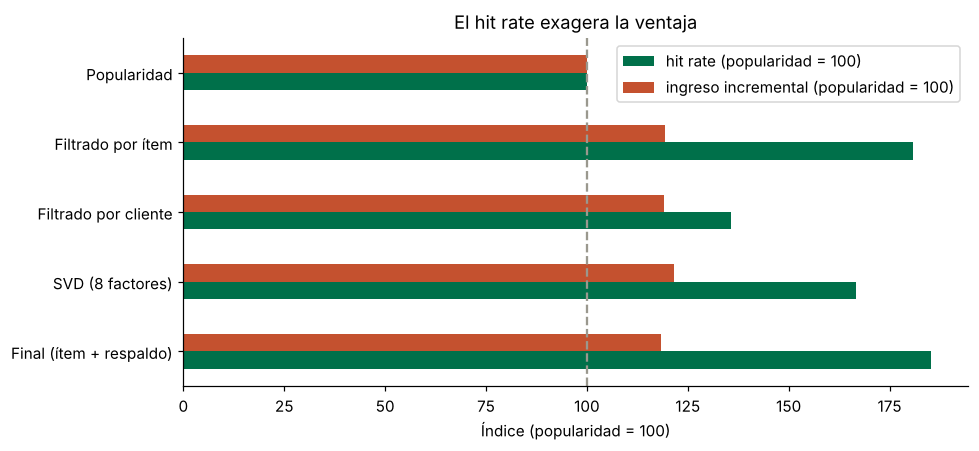

In [16]:
tk_pop = top_k(S_pop)
real_trat = (pi[filas_, tk_pop] * precio_v[tk_pop]).sum(axis=1)[~es_control].mean()
print(f"Efecto VERDADERO del carrusel (ingreso por cliente tratado): ${real_trat:.2f}")
print(f"Lo que midió su experimento (Paso 3): ${delta_arpu:+.2f} · IC 95% {ic_arpu[0]:+.2f} a {ic_arpu[1]:+.2f}  →  ¿cae dentro?  {ic_arpu[0] <= real_trat <= ic_arpu[1]}")

idx = pd.DataFrame({
    "hit rate (popularidad = 100)": rev["hit rate@3 (control)"] / rev.loc["Popularidad", "hit rate@3 (control)"] * 100,
    "ingreso incremental (popularidad = 100)": rev["ingreso incremental esperado (US$/cliente)"] / rev.loc["Popularidad", "ingreso incremental esperado (US$/cliente)"] * 100,
})
ax = idx.iloc[::-1].plot.barh(color=[VERDE, NARANJA], figsize=(9, 4.2))
ax.axvline(100, color=GRIS, linestyle="--"); ax.set_xlabel("Índice (popularidad = 100)"); ax.set_title("El hit rate exagera la ventaja")
plt.tight_layout(); plt.show()

In [17]:
# ¿A todos hay que mostrarles el carrusel? El efecto depende de qué tan receptivo es cada cliente (columna oculta)
cuartil = pd.qcut(vo_cl["receptividad"], 4, labels=["Q1 (menos receptivos)", "Q2", "Q3", "Q4 (más receptivos)"])
tk = top_k(S_item)
inc_usd_item = (pi[filas_, tk] * precio_v[tk]).sum(axis=1)
pd.Series(inc_usd_item).groupby(cuartil.values).mean().round(2).rename("ingreso incremental esperado (US$/cliente) · filtrado por ítem")

Q1 (menos receptivos)    0.47
Q2                       0.94
Q3                       1.38
Q4 (más receptivos)      1.98
Name: ingreso incremental esperado (US$/cliente) · filtrado por ítem, dtype: float64

**Respuestas Paso 5**

1. Si, el efecto verdadero del carrusel es de 0.99 dolares por cliente tratado y cae dentro del intervalo que midio el experimento, que iba de 0.37 a 1.86. El experimento A/B recupero bien el efecto real.

2. La ventaja del filtrado por item sobre la popularidad es mucho mayor en hit rate que en ingreso incremental. En hit rate casi lo duplica, pero en ingreso incremental esperado la diferencia es pequena, cerca de 1.19 contra 1.00 dolares. El hit rate exagera la ventaja porque premia acertar cualquier compra, aunque esa compra ya fuera a ocurrir sola.

3. Una parte alta de las compras acertadas ya iba a ocurrir de todos modos: cerca del 44 por ciento en el filtrado por item y un 31 por ciento en popularidad. Significa que un directivo que solo mire el hit rate sobreestima el ingreso extra, porque confunde compras que el recomendador causo con compras que solo coincidio en adivinar.

4. No conviene mostrar el carrusel a todos. El ingreso incremental crece fuerte con la receptividad, de 0.47 dolares en el cuartil menos receptivo a 1.98 en el mas receptivo. La tecnica de la Semana 3 que ayuda a decidir a quien mostrarlo es el modelo de uplift, que estima el efecto incremental por cliente y permite concentrar el carrusel en los mas persuadibles.

## Para entregar

1. El notebook completo, **ejecutado de principio a fin**, con sus respuestas a las preguntas de cada paso.
2. **Su propia app de Streamlit** (usen `streamlit_starter.py` como punto de partida) que le permita a alguien de
   negocio explorar los recomendadores: elegir un cliente y un método, ver sus **3 recomendaciones con el "porque"**, y la
   tabla de comparación (hit rate y cobertura) — con al menos un control interactivo (slider o selector).
3. Una conclusión de una página para el Presidente de Marketing: ¿qué recomendador llevarían al siguiente experimento,
   cuánto vale (ΔARPU y ΔCLV) y qué tan cerca estuvo el hit rate de la verdad?